In [ ]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# Membaca file CSV transaksi
data_raw = pd.read_csv('transactions_arm_praktikum.csv')

# Mengubah string item menjadi list of lists untuk variabel 'transactions'
transactions = data_raw['Items'].apply(lambda x: [item.strip() for item in x.split(',')]).tolist()

print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

4.1 Persiapan Data Transaksi

In [ ]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# transactions: list berisi 60 transaksi (daftar item per transaksi)
print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Mengecek Frekuensi Kemunculan Tiap Item

In [ ]:
from collections import Counter
cnt = Counter()
for t in transactions:
    cnt.update(t)
for item, freq in cnt.most_common():
    print(f'{item:12s}: {freq:2d}  (support = {freq/len(transactions):.3f})')

Susu        : 19  (support = 0.317)
Roti        : 18  (support = 0.300)
Mie Instan  : 18  (support = 0.300)
Mentega     : 17  (support = 0.283)
Telur       : 15  (support = 0.250)
Sabun       : 15  (support = 0.250)
Gula        : 14  (support = 0.233)
Kopi        : 13  (support = 0.217)
Shampo      : 13  (support = 0.217)
Kecap       : 12  (support = 0.200)
Keju        :  6  (support = 0.100)
Teh         :  4  (support = 0.067)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

4.2 Encoding Data Transaksi ke Format One-Hot

In [ ]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

4.3 Mencari Frequent Itemset dengan Algoritma Apriori

In [ ]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)
print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.to_string(index=False))

4.4 Membentuk Aturan Asosiasi

In [ ]:
MIN_CONF = 0.5
rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
print('Jumlah aturan asosiasi:', len(rules))
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
print(rules[cols].round(3).to_string(index=False))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Jumlah aturan asosiasi: 18
    antecedents     consequents  support  confidence  lift
(Mentega, Susu)          (Roti)    0.183       1.000 3.333
         (Roti) (Mentega, Susu)    0.183       0.611 3.333
   (Roti, Susu)       (Mentega)    0.183       0.846 2.986
      (Mentega)    (Roti, Susu)    0.183       0.647 2.986
        (Sabun)        (Shampo)    0.150       0.600 2.769
       (Shampo)         (Sabun)    0.150       0.692 2.769
         (Susu) (Roti, Mentega)    0.183       0.579 2.672
(Roti, Mentega)          (Susu)    0.183       0.846 2.672
         (Roti)       (Mentega)    0.217       0.722 2.549
      (Mentega)          (Roti)    0.217       0.765 2.549
   (Mie Instan)         (Kecap)    0.150       0.500 2.500
        (Kecap)    (Mie Instan)    0.150       0.750 2.500
         (Roti)          (Susu)    0.217       0.722 2.281
         (Susu)          (Roti)    0.217       0.684 2.281
        (Telur)    (Mie Instan)    0.167       0.667 2.222
   (Mie Instan)         (Telu

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

4.5 Visualisasi Hasil (Scatter Plot)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

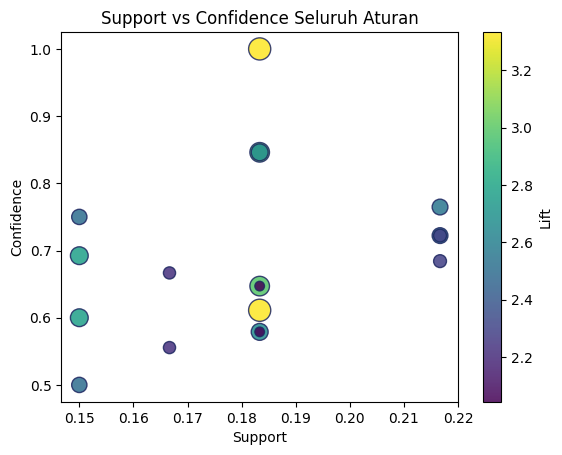

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import matplotlib.pyplot as plt

sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes,
                 c=rules['lift'], cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Seluruh Aturan')
plt.show()

4.7 Eksperimen: Pengaruh Nilai min_support

In [ ]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

4.8 Eksperimen: Apriori vs FP-Growth

In [ ]:
import time

t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)
t_apriori = time.perf_counter() - t0

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.15, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])

print(f'Apriori : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori : 17 itemset, 7.37 ms
FP-Growth: 17 itemset, 13.39 ms
Itemset identik? True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag